# Module 4 - Machine Learning Fundamentals
**What this module covers:** supervised 4-class classification of accident `Severity` with **Decision Tree**,
**Random Forest**, **Logistic Regression** and **HistGradientBoosting** (extra model) in one scikit-learn
`Pipeline` + `ColumnTransformer`, stratified 80/20 split, `class_weight="balanced"`, 3-fold randomized search on
macro-F1, evaluation with and without `Distance(mi)` (accuracy, macro/weighted F1, per-class reports, normalized
confusion matrices, ROC one-vs-rest), 5-fold CV of the best model and permutation feature importance.

**Project task satisfied here:** *ML: Decision Tree, Random Forest, Logistic Regression.*

**Headline metric:** macro-F1 (every severity level counts equally), always shown next to accuracy and the
majority-class baseline.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import randint, loguniform, uniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.tree import plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, roc_curve
from sklearn.preprocessing import label_binarize
from src import utils as U, viz as V, modeling as M, train_final as T

V.apply_style()
FIG, MET = U.FIGURES, U.METRICS
RS = U.RANDOM_STATE
NAMES = M.MODEL_NAMES
MODEL_COLORS = dict(zip(NAMES, V.CATEGORICAL[:4]))
df = pd.read_parquet(U.CLEAN_PARQUET)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| interpreter:", Path(sys.executable).parent.parent.name)
import sklearn; print("scikit-learn", sklearn.__version__)

Python 3.14.2 | pandas 3.1.0 | interpreter: .venv
scikit-learn 1.9.1


## 1. Features and leakage control
| Used | Not used (and why) |
|---|---|
| Start_Lat, Start_Lng, State, City (frequency + top-30 one-hot) | `End_Time`, `Duration_min`: known only after the accident is cleared (leakage) |
| Temperature, Humidity, Pressure, Visibility, Wind speed, Precipitation, WeatherGroup, Wind_Direction | `Distance(mi)`: length of road affected, measured after the event - **run both ways, headline = without** |
| Hour, DayOfWeek, Month, IsWeekend, IsRushHour, DayNight | `Year`: data-collection artefact (severe share falls year by year, Module 2) |
| 12 road-feature flags + RoadFeatureCount | `Source`: data-provider artefact; `ID`; free text (`Description` dropped in Module 1) |

In [2]:
X_train, X_test, y_train, y_test = T.split(df, with_distance=True)   # same rows as T.split(df, False), one more column
FEATS = {False: M.feature_columns(False), True: M.feature_columns(True)}
split = pd.DataFrame({"train": y_train.value_counts().sort_index(), "test": y_test.value_counts().sort_index()})
split["train_pct"] = (100 * split["train"] / split["train"].sum()).round(2)
split["test_pct"] = (100 * split["test"] / split["test"].sum()).round(2)
print(f"Train rows: {len(X_train):,}  Test rows: {len(X_test):,}")
split

Train rows: 319,664  Test rows: 79,917


,train,test,train_pct,test_pct
Severity,,,,
1,2786,696,0.87,0.87
2,254629,63658,79.66,79.66
3,53785,13447,16.83,16.83
4,8464,2116,2.65,2.65


## 2. Majority-class baseline

In [3]:
maj = y_train.mode().iloc[0]
baseline = M.evaluate(y_test, np.full(len(y_test), maj))
print(f"Always predict Severity {maj}: accuracy={baseline['accuracy']}, macro-F1={baseline['macro_f1']}")

Always predict Severity 2: accuracy=0.7966, macro-F1=0.2217


## 3. Hyper-parameter search (RandomizedSearchCV, 3-fold, scoring = macro-F1)
Run on the full training set, without Distance, with `class_weight="balanced"` for every model.

In [4]:
cv3 = StratifiedKFold(3, shuffle=True, random_state=RS)
spaces = {
    "Decision Tree": ({"model__max_depth": randint(6, 31), "model__min_samples_leaf": randint(1, 101),
                       "model__criterion": ["gini", "entropy"]}, 15, 4),
    "Random Forest": ({"model__n_estimators": [100, 150, 200], "model__max_depth": randint(12, 31),
                       "model__min_samples_leaf": randint(1, 21), "model__max_features": ["sqrt", 0.3]}, 8, 1),
    "Logistic Regression": ({"model__C": loguniform(1e-3, 1e2)}, 6, 4),
    "HistGradientBoosting": ({"model__learning_rate": loguniform(0.03, 0.3), "model__max_iter": [200, 300, 400],
                              "model__max_leaf_nodes": randint(15, 128), "model__min_samples_leaf": randint(20, 201),
                              "model__l2_regularization": loguniform(1e-3, 10)}, 8, 1),
}
best_params, search_rows = {}, []
for name, (space, n_iter, n_jobs) in spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(M.build_pipeline(name, with_distance=False), space, n_iter=n_iter, scoring="f1_macro",
                            cv=cv3, random_state=RS, n_jobs=n_jobs, refit=False)
    rs.fit(X_train[FEATS[False]], y_train)
    best_params[name] = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in rs.best_params_.items()}
    search_rows.append({"model": name, "n_iter": n_iter, "cv_folds": 3, "best_cv_macro_f1": round(rs.best_score_, 4),
                        "best_params": json.dumps(best_params[name]), "search_seconds": round(time.time() - t0, 1)})
    print(f"{name}: best 3-fold macro-F1={rs.best_score_:.4f}  params={best_params[name]}  ({time.time() - t0:.0f} s)")
search = pd.DataFrame(search_rows); search.to_csv(MET / "hyperparameter_search.csv", index=False)
search

Decision Tree: best 3-fold macro-F1=0.3435  params={'criterion': 'entropy', 'max_depth': 26, 'min_samples_leaf': 2}  (107 s)


Random Forest: best 3-fold macro-F1=0.3753  params={'max_depth': 17, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 150}  (323 s)


Logistic Regression: best 3-fold macro-F1=0.2587  params={'C': 4.5705630998014515}  (122 s)


HistGradientBoosting: best 3-fold macro-F1=0.3714  params={'l2_regularization': 0.06672367170464207, 'learning_rate': 0.18293517328594538, 'max_iter': 400, 'max_leaf_nodes': 122, 'min_samples_leaf': 74}  (514 s)


,model,n_iter,cv_folds,best_cv_macro_f1,best_params,search_seconds
0,Decision Tree,15,3,0.3435,"{""criterion"": ""entropy"", ""max_depth"": 26, ""min...",107.2
1,Random Forest,8,3,0.3753,"{""max_depth"": 17, ""max_features"": 0.3, ""min_sa...",323.1
2,Logistic Regression,6,3,0.2587,"{""C"": 4.5705630998014515}",122.1
3,HistGradientBoosting,8,3,0.3714,"{""l2_regularization"": 0.06672367170464207, ""le...",514.4


## 4. Fit the tuned models - without and with `Distance(mi)`

In [5]:
results, fitted, preds, probas = [], {}, {}, {}
for with_d in (False, True):
    for name in NAMES:
        t0 = time.time()
        pipe = M.build_pipeline(name, best_params[name], with_distance=with_d).fit(X_train[FEATS[with_d]], y_train)
        secs = time.time() - t0
        pr = pipe.predict(X_test[FEATS[with_d]]); pp = pipe.predict_proba(X_test[FEATS[with_d]])
        ev = M.evaluate(y_test, pr, pp)
        results.append({"model": name, "distance_feature": "with" if with_d else "without", "class_weight": "balanced",
                        "train_seconds": round(secs, 1), **ev})
        fitted[(name, with_d)], preds[(name, with_d)], probas[(name, with_d)] = pipe, pr, pp
        print(f"{name:21s} {'with' if with_d else 'without':7s} Distance: acc={ev['accuracy']:.4f} macro-F1={ev['macro_f1']:.4f} "
              f"ROC-AUC={ev['roc_auc_ovr_macro']:.4f} ({secs:.0f} s)")
for d in ("without", "with"):
    results.append({"model": "Majority baseline", "distance_feature": d, "class_weight": "-", "train_seconds": 0, **baseline})
comp = pd.DataFrame(results)
comp.to_csv(MET / "model_comparison.csv", index=False)
cols = ["model", "distance_feature", "accuracy", "macro_f1", "weighted_f1", "balanced_accuracy", "roc_auc_ovr_macro",
        "recall_sev1", "recall_sev2", "recall_sev3", "recall_sev4", "train_seconds"]
comp[cols]

Decision Tree         without Distance: acc=0.6490 macro-F1=0.3530 ROC-AUC=0.6272 (13 s)


Random Forest         without Distance: acc=0.5946 macro-F1=0.3751 ROC-AUC=0.8096 (24 s)


Logistic Regression   without Distance: acc=0.3744 macro-F1=0.2610 ROC-AUC=0.7353 (29 s)


HistGradientBoosting  without Distance: acc=0.5899 macro-F1=0.3805 ROC-AUC=0.8278 (17 s)


Decision Tree         with    Distance: acc=0.7028 macro-F1=0.4138 ROC-AUC=0.6844 (14 s)


Random Forest         with    Distance: acc=0.6313 macro-F1=0.4206 ROC-AUC=0.8721 (23 s)


Logistic Regression   with    Distance: acc=0.3899 macro-F1=0.2734 ROC-AUC=0.7500 (27 s)


HistGradientBoosting  with    Distance: acc=0.6402 macro-F1=0.4312 ROC-AUC=0.8868 (17 s)


,model,distance_feature,accuracy,macro_f1,weighted_f1,balanced_accuracy,roc_auc_ovr_macro,recall_sev1,recall_sev2,recall_sev3,recall_sev4,train_seconds
0,Decision Tree,without,0.6490,0.3530,0.6852,0.4265,0.6272,0.3075,0.7057,0.4643,0.2287,13.0
1,Random Forest,without,0.5946,0.3751,0.6525,0.5902,0.8096,0.6537,0.5867,0.6482,0.4721,23.6
2,Logistic Regression,without,0.3744,0.2610,0.4603,0.5299,0.7353,0.7069,0.3426,0.4726,0.5974,28.9
3,HistGradientBoosting,without,0.5899,0.3805,0.6524,0.6273,0.8278,0.7011,0.5737,0.6636,0.5709,17.3
4,Decision Tree,with,0.7028,0.4138,0.7322,0.5086,0.6844,0.3966,0.7430,0.5915,0.3034,13.9
5,Random Forest,with,0.6313,0.4206,0.6881,0.6946,0.8721,0.7457,0.6054,0.7392,0.6881,23.4
6,Logistic Regression,with,0.3899,0.2734,0.4739,0.5585,0.7500,0.7543,0.3525,0.5127,0.6144,26.9
7,HistGradientBoosting,with,0.6402,0.4312,0.6978,0.7174,0.8868,0.7687,0.6102,0.7613,0.7292,17.3
8,Majority baseline,without,0.7966,0.2217,0.7063,0.2500,NaN,0.0000,1.0000,0.0000,0.0000,0.0
9,Majority baseline,with,0.7966,0.2217,0.7063,0.2500,NaN,0.0000,1.0000,0.0000,0.0000,0.0


## 5. Per-class reports and normalized confusion matrices (without Distance)

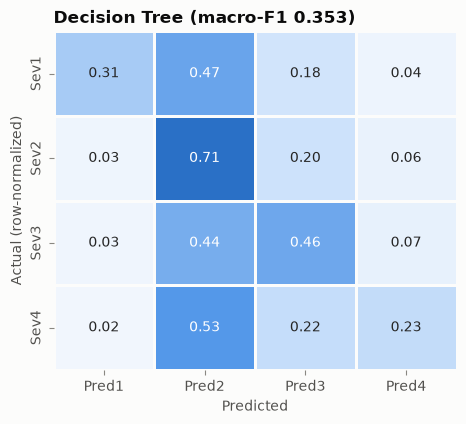

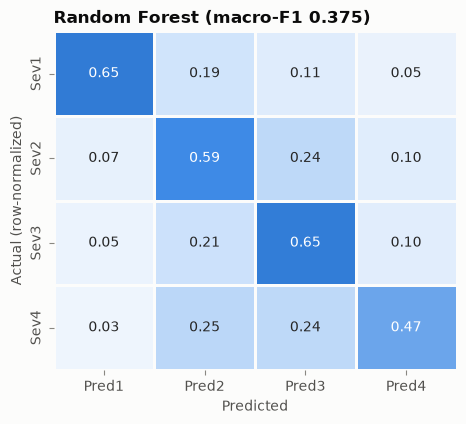

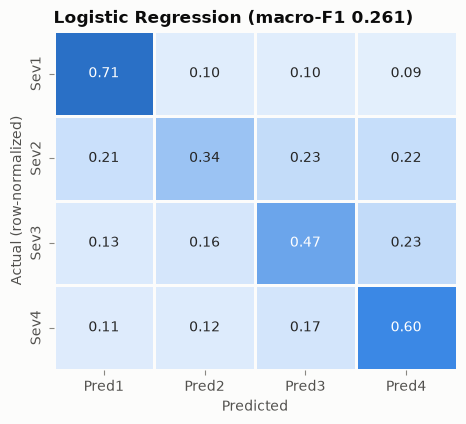

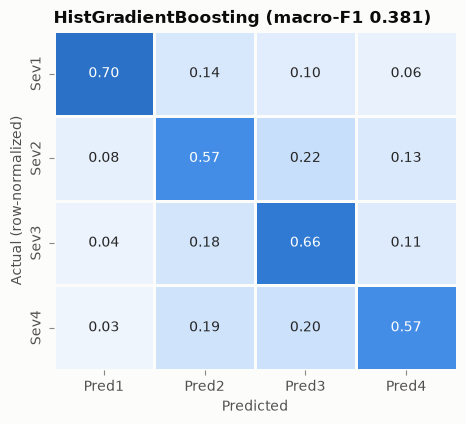

In [6]:
for name in NAMES:
    rep = pd.DataFrame(classification_report(y_test, preds[(name, False)], labels=M.LABELS, output_dict=True, zero_division=0)).T
    rep.index = [f"Severity {i}" if str(i).isdigit() else i for i in rep.index]
    rep.round(4).to_csv(MET / f"classification_report_{M.slug(name)}.csv", index_label="class")
    cm = M.normalized_confusion(y_test, preds[(name, False)])
    cm.round(4).to_csv(MET / f"confusion_{M.slug(name)}.csv")
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=V.SEQ_CMAP, vmin=0, vmax=1, ax=ax, cbar=False, linewidths=1, linecolor=V.SURFACE)
    mf = comp[(comp.model == name) & (comp.distance_feature == "without")]["macro_f1"].iloc[0]
    ax.set(title=f"{name} (macro-F1 {mf:.3f})", xlabel="Predicted", ylabel="Actual (row-normalized)"); ax.grid(False)
    V.save(fig, FIG / f"confusion_{M.slug(name)}.png")

## 6. ROC comparison (one-vs-rest, macro-average, without Distance)

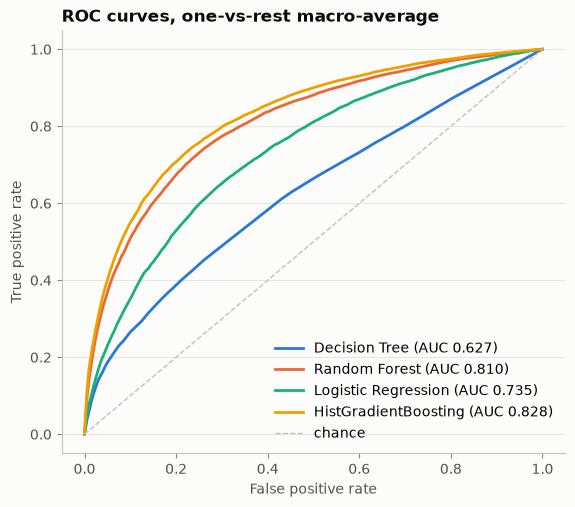

In [7]:
Yb = label_binarize(y_test, classes=M.LABELS)
grid = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in NAMES:
    pp = probas[(name, False)]
    tprs = [np.interp(grid, *roc_curve(Yb[:, i], pp[:, i])[:2]) for i in range(len(M.LABELS))]
    auc = comp[(comp.model == name) & (comp.distance_feature == "without")]["roc_auc_ovr_macro"].iloc[0]
    ax.plot(grid, np.mean(tprs, axis=0), color=MODEL_COLORS[name], label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=V.AXIS, ls="--", lw=1, label="chance")
ax.set(title="ROC curves, one-vs-rest macro-average", xlabel="False positive rate", ylabel="True positive rate"); ax.legend(loc="lower right")
V.save(fig, FIG / "roc_comparison.png")

## 7. Class-weighting scheme: inverse ("balanced") vs square root (re-test of the upstream idea)

In [8]:
wrows = []
sw = M.sqrt_balanced_weights(y_train)
for name in NAMES:
    pipe = M.build_pipeline(name, best_params[name], with_distance=False)
    pipe.set_params(model__class_weight=None)
    pipe.fit(X_train[FEATS[False]], y_train, model__sample_weight=sw)
    ev = M.evaluate(y_test, pipe.predict(X_test[FEATS[False]]), pipe.predict_proba(X_test[FEATS[False]]))
    inv = comp[(comp.model == name) & (comp.distance_feature == "without")].iloc[0]
    for scheme, e in (("inverse (balanced)", inv), ("sqrt", ev)):
        wrows.append({"model": name, "weights": scheme, "accuracy": e["accuracy"], "macro_f1": e["macro_f1"],
                      "weighted_f1": e["weighted_f1"], "recall_sev1": e["recall_sev1"], "recall_sev4": e["recall_sev4"]})
wcomp = pd.DataFrame(wrows); wcomp.to_csv(MET / "class_weight_comparison.csv", index=False)
wcomp

,model,weights,accuracy,macro_f1,weighted_f1,recall_sev1,recall_sev4
0,Decision Tree,inverse (balanced),0.6490,0.3530,0.6852,0.3075,0.2287
1,Decision Tree,sqrt,0.7007,0.3703,0.7187,0.2126,0.1805
2,Random Forest,inverse (balanced),0.5946,0.3751,0.6525,0.6537,0.4721
3,Random Forest,sqrt,0.7984,0.4262,0.7839,0.1322,0.1493
4,Logistic Regression,inverse (balanced),0.3744,0.2610,0.4603,0.7069,0.5974
5,Logistic Regression,sqrt,0.7674,0.3502,0.7458,0.1264,0.0699
6,HistGradientBoosting,inverse (balanced),0.5899,0.3805,0.6524,0.7011,0.5709
7,HistGradientBoosting,sqrt,0.7879,0.4637,0.7910,0.3046,0.2401


## 8. Best model (highest macro-F1 without Distance) and 5-fold cross-validation

In [9]:
main = comp[(comp.distance_feature == "without") & (comp.model != "Majority baseline")].sort_values("macro_f1", ascending=False)
best_name = main.iloc[0]["model"]
print(f"Best model: {best_name}  macro-F1={main.iloc[0]['macro_f1']}  accuracy={main.iloc[0]['accuracy']}")
print(classification_report(y_test, preds[(best_name, False)], digits=4))
dist = comp[comp.model == best_name].set_index("distance_feature")
t0 = time.time()
cvres = cross_validate(M.build_pipeline(best_name, best_params[best_name]), X_train[FEATS[False]], y_train,
                       cv=StratifiedKFold(5, shuffle=True, random_state=RS), scoring=["f1_macro", "accuracy"], n_jobs=1)
cv_summary = {"folds": 5, "macro_f1_mean": round(float(cvres["test_f1_macro"].mean()), 4), "macro_f1_std": round(float(cvres["test_f1_macro"].std()), 4),
              "accuracy_mean": round(float(cvres["test_accuracy"].mean()), 4), "accuracy_std": round(float(cvres["test_accuracy"].std()), 4),
              "macro_f1_per_fold": [round(float(v), 4) for v in cvres["test_f1_macro"]]}
print(cv_summary, f"({time.time() - t0:.0f} s)")

Best model: HistGradientBoosting  macro-F1=0.3805  accuracy=0.5899
              precision    recall  f1-score   support

           1     0.0822    0.7011    0.1472       696
           2     0.9264    0.5737    0.7086     63658
           3     0.3842    0.6636    0.4867     13447
           4     0.1066    0.5709    0.1796      2116

    accuracy                         0.5899     79917
   macro avg     0.3749    0.6273    0.3805     79917
weighted avg     0.8061    0.5899    0.6524     79917



{'folds': 5, 'macro_f1_mean': 0.3713, 'macro_f1_std': 0.0017, 'accuracy_mean': 0.5765, 'accuracy_std': 0.0027, 'macro_f1_per_fold': [0.3724, 0.3723, 0.373, 0.3702, 0.3685]} (64 s)


## 9. Permutation feature importance of the best model
Each input column is shuffled in turn on a stratified 20,000-row test subsample; the drop in macro-F1
(mean of 5 repeats) measures how much the model relies on it.

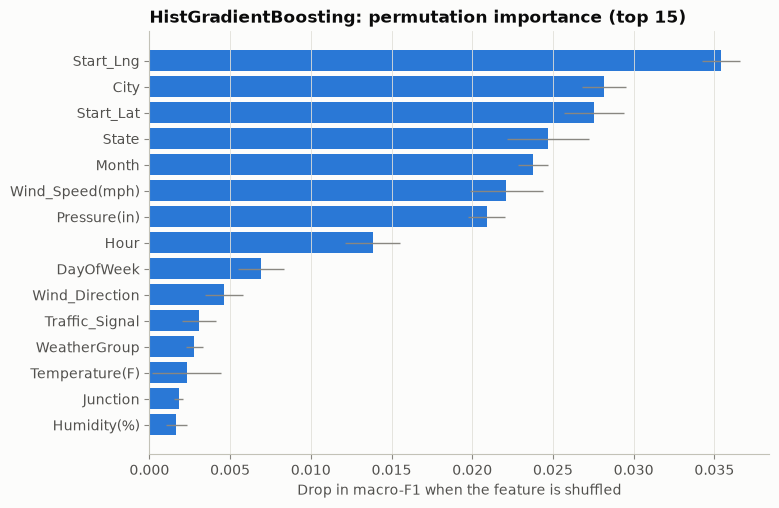

(29 s)


,feature,importance_mean,importance_std
1,Start_Lng,0.03540,0.00118
30,City,0.02818,0.00137
0,Start_Lat,0.02757,0.00186
26,State,0.02470,0.00256
10,Month,0.02376,0.00091
6,Wind_Speed(mph),0.02211,0.00228
4,Pressure(in),0.02089,0.00115
8,Hour,0.01383,0.00169
9,DayOfWeek,0.00692,0.00144
29,Wind_Direction,0.00462,0.00119


In [10]:
_, X_pi, _, y_pi = train_test_split(X_test[FEATS[False]], y_test, test_size=20_000, stratify=y_test, random_state=RS)
t0 = time.time()
pi = permutation_importance(fitted[(best_name, False)], X_pi, y_pi, scoring="f1_macro", n_repeats=5, random_state=RS, n_jobs=1)
fi = pd.DataFrame({"feature": X_pi.columns, "importance_mean": pi.importances_mean, "importance_std": pi.importances_std})
fi = fi.sort_values("importance_mean", ascending=False).round(5)
fi.to_csv(MET / "feature_importance.csv", index=False)
top = fi.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color=V.PRIMARY, error_kw={"ecolor": V.MUTED, "lw": 1})
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title=f"{best_name}: permutation importance (top 15)", xlabel="Drop in macro-F1 when the feature is shuffled")
V.save(fig, FIG / "feature_importance_top15.png")
print(f"({time.time() - t0:.0f} s)")
fi.head(10)

## 10. Save the best model and its summary

In [11]:
bm = main.iloc[0]
pipe, mb = T.train_and_save(best_name, best_params[best_name], df)
assert (pipe.predict(X_test[FEATS[False]]) == preds[(best_name, False)]).all(), "saved model differs from the evaluated one"
best_json = {"best_model": best_name, "with_distance": False, "selection": "highest test macro-F1, without Distance(mi)",
             "params": best_params[best_name],
             "test": {k: bm[k] for k in ["accuracy", "macro_f1", "weighted_f1", "balanced_accuracy", "roc_auc_ovr_macro",
                                         "recall_sev1", "recall_sev2", "recall_sev3", "recall_sev4"]},
             "test_with_distance": {k: dist.loc["with", k] for k in ["accuracy", "macro_f1", "roc_auc_ovr_macro"]},
             "cv_5fold": cv_summary, "baseline_majority": {k: baseline[k] for k in ["accuracy", "macro_f1"]},
             "train_rows": len(X_train), "test_rows": len(X_test), "random_state": RS,
             "features": FEATS[False], "model_file": "models/best_model.joblib", "model_file_mb": round(mb, 1)}
U.save_json(best_json, MET / "best_model.json")
print(f"Saved models/best_model.joblib ({mb:.1f} MB); {'committed' if mb <= 50 else 'over 50 MB -> git-ignored, rebuild with: python -m src.train_final'}")

Saved models/best_model.joblib (1.0 MB); committed


## 11. Model comparison chart, Logistic Regression coefficients, Decision Tree

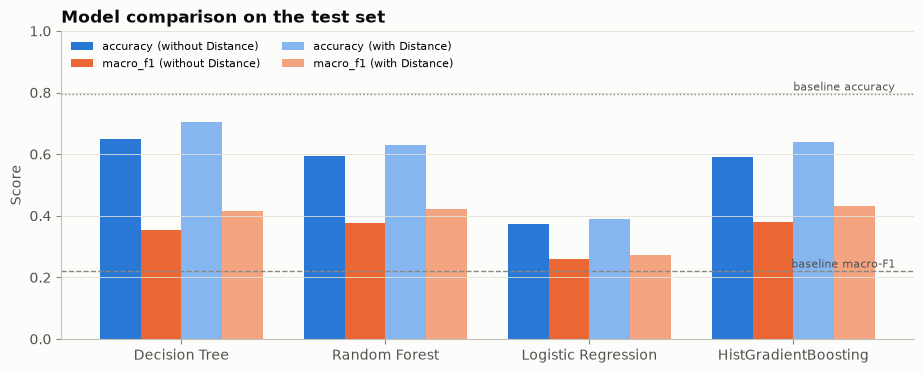

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(NAMES)); w = 0.2
for i, (metric, d, col) in enumerate([("accuracy", "without", V.CATEGORICAL[0]), ("macro_f1", "without", V.CATEGORICAL[1]),
                                      ("accuracy", "with", "#86b6ef"), ("macro_f1", "with", "#f3a582")]):
    vals = [comp[(comp.model == n) & (comp.distance_feature == d)][metric].iloc[0] for n in NAMES]
    ax.bar(x + (i - 1.5) * w, vals, w, color=col, label=f"{metric} ({d} Distance)")
ax.axhline(baseline["macro_f1"], color=V.MUTED, ls="--", lw=1)
ax.axhline(baseline["accuracy"], color=V.MUTED, ls=":", lw=1)
ax.text(len(NAMES) - 0.5, baseline["macro_f1"] + 0.01, "baseline macro-F1", fontsize=8, color=V.INK2, ha="right")
ax.text(len(NAMES) - 0.5, baseline["accuracy"] + 0.01, "baseline accuracy", fontsize=8, color=V.INK2, ha="right")
ax.set_xticks(x); ax.set_xticklabels(NAMES); ax.set(title="Model comparison on the test set", ylabel="Score", ylim=(0, 1))
ax.legend(ncol=2, fontsize=8, loc="upper left")
V.save(fig, FIG / "ml_model_comparison.png")

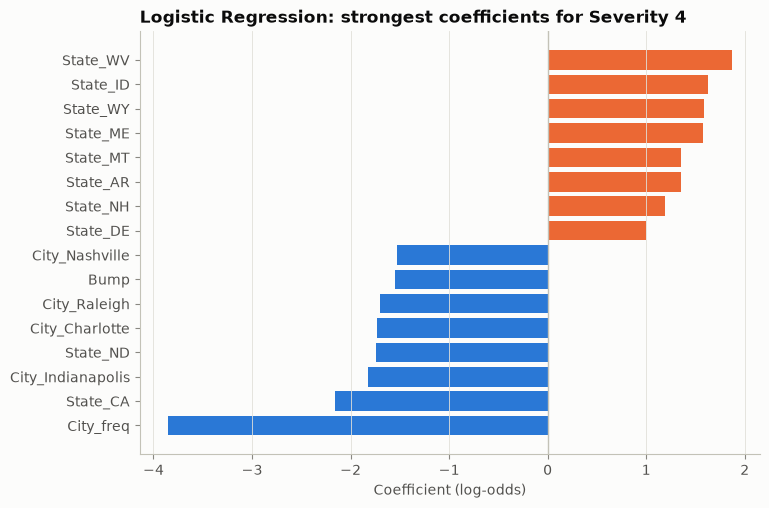

In [13]:
lr = fitted[("Logistic Regression", False)]
coef = pd.DataFrame(lr.named_steps["model"].coef_.T, index=lr.named_steps["prep"].get_feature_names_out(),
                    columns=[f"Sev{c}" for c in lr.named_steps["model"].classes_])
coef.round(4).to_csv(MET / "lr_coefficients.csv")
top4 = coef["Sev4"].sort_values(); sel = pd.concat([top4.head(8), top4.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(sel.index, sel.values, color=[V.CATEGORICAL[0] if v < 0 else V.CATEGORICAL[1] for v in sel.values])
ax.axvline(0, color=V.AXIS, lw=1); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Logistic Regression: strongest coefficients for Severity 4", xlabel="Coefficient (log-odds)")
V.save(fig, FIG / "ml_lr_coefficients.png")

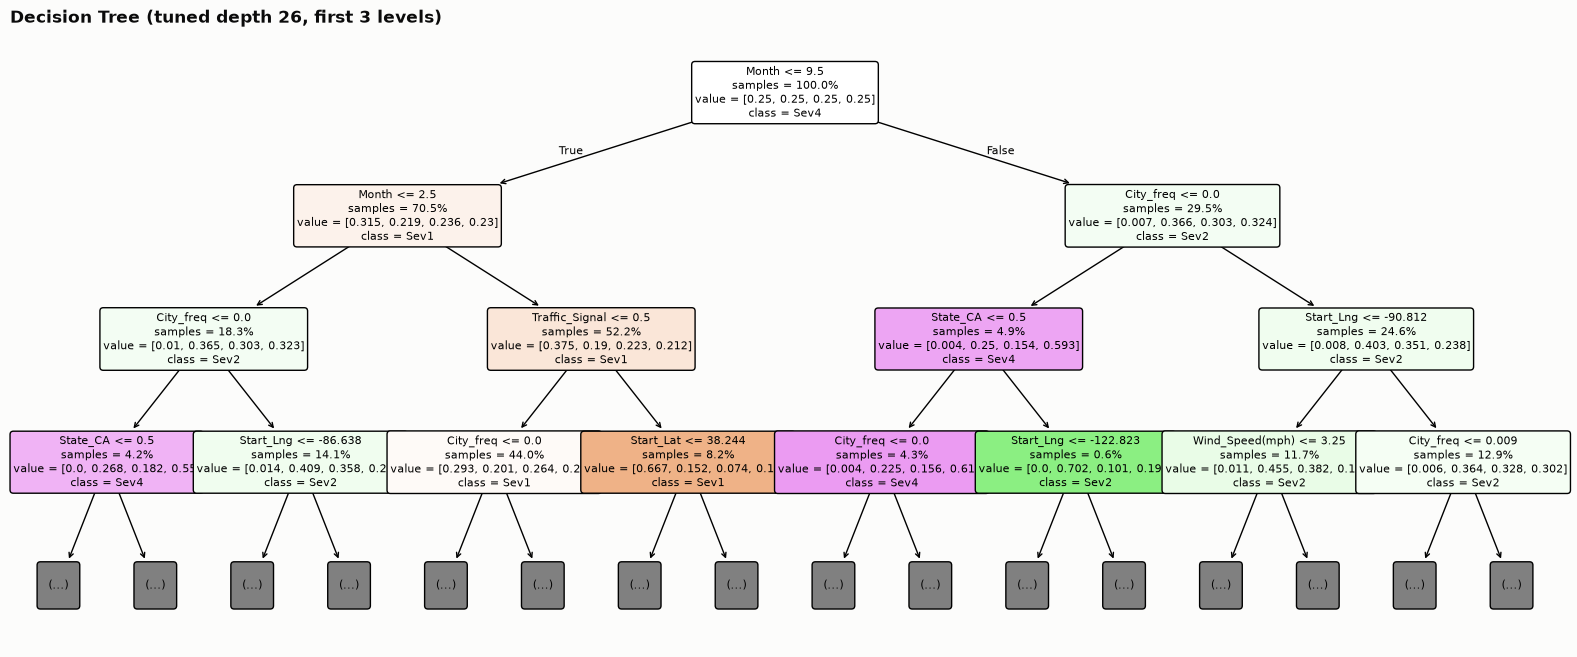

In [14]:
dt = fitted[("Decision Tree", False)]
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt.named_steps["model"], max_depth=3, feature_names=dt.named_steps["prep"].get_feature_names_out(),
          class_names=[f"Sev{c}" for c in dt.named_steps["model"].classes_], filled=True, impurity=False,
          proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Decision Tree (tuned depth {dt.named_steps['model'].get_depth()}, first 3 levels)")
V.save(fig, FIG / "ml_decision_tree.png")

In [15]:
wl = wcomp.set_index(["model", "weights"])
summary = {
    "best": f"{best_name} has the best macro-F1 ({bm['macro_f1']:.3f}, accuracy {bm['accuracy']:.3f}) vs the majority "
            f"baseline ({baseline['macro_f1']:.3f} macro-F1, {baseline['accuracy']:.3f} accuracy).",
    "distance": f"Adding Distance(mi) changes {best_name}'s macro-F1 from {dist.loc['without', 'macro_f1']:.3f} to {dist.loc['with', 'macro_f1']:.3f}.",
    "weights": f"For {best_name}, sqrt weights give accuracy {wl.loc[(best_name, 'sqrt'), 'accuracy']:.3f} / macro-F1 "
               f"{wl.loc[(best_name, 'sqrt'), 'macro_f1']:.3f} / Severity-4 recall {wl.loc[(best_name, 'sqrt'), 'recall_sev4']:.3f} vs balanced "
               f"{wl.loc[(best_name, 'inverse (balanced)'), 'accuracy']:.3f} / {wl.loc[(best_name, 'inverse (balanced)'), 'macro_f1']:.3f} / "
               f"{wl.loc[(best_name, 'inverse (balanced)'), 'recall_sev4']:.3f}.",
    "top_features": f"Top permutation-importance features: {fi.iloc[0]['feature']}, {fi.iloc[1]['feature']}, {fi.iloc[2]['feature']}.",
    "cv": f"5-fold CV macro-F1 of {best_name}: {cv_summary['macro_f1_mean']:.3f} +/- {cv_summary['macro_f1_std']:.3f}.",
}
U.save_json(summary, MET / "ml_insights.json")
for v in summary.values(): print("-", v)

- HistGradientBoosting has the best macro-F1 (0.381, accuracy 0.590) vs the majority baseline (0.222 macro-F1, 0.797 accuracy).
- Adding Distance(mi) changes HistGradientBoosting's macro-F1 from 0.381 to 0.431.
- For HistGradientBoosting, sqrt weights give accuracy 0.788 / macro-F1 0.464 / Severity-4 recall 0.240 vs balanced 0.590 / 0.381 / 0.571.
- Top permutation-importance features: Start_Lng, City, Start_Lat.
- 5-fold CV macro-F1 of HistGradientBoosting: 0.371 +/- 0.002.


## 12. Conclusions (generated from `model_comparison.csv`, `best_model.json`, `feature_importance.csv`)

In [16]:
below = main[main["accuracy"] < baseline["accuracy"]]["model"].tolist()
display(Markdown(f"""
* **Best model:** {best_name} - macro-F1 **{bm['macro_f1']:.3f}**, accuracy {bm['accuracy']:.3f}, ROC-AUC {bm['roc_auc_ovr_macro']:.3f}
  (5-fold CV macro-F1 {cv_summary['macro_f1_mean']:.3f} +/- {cv_summary['macro_f1_std']:.3f}).
* **Accuracy vs the baseline:** always predicting Severity {maj} scores accuracy {baseline['accuracy']:.3f} but macro-F1 only
  {baseline['macro_f1']:.3f}. {len(below)} of {len(main)} models ({', '.join(below) if below else 'none'}) have lower accuracy than this
  baseline, because balanced class weights move predictions towards the rare classes. Accuracy rewards ignoring Severity 1, 3
  and 4, so **macro-F1** (the mean F1 of the four classes) is the headline metric.
* **Severe-class recall ({best_name}):** Severity 3 = {bm['recall_sev3']:.3f}, Severity 4 = {bm['recall_sev4']:.3f}
  (Severity 1 = {bm['recall_sev1']:.3f}, Severity 2 = {bm['recall_sev2']:.3f}).
* **Why Distance(mi) is excluded:** it is the length of road affected, measured after the accident. Adding it raises macro-F1
  from {dist.loc['without', 'macro_f1']:.3f} to {dist.loc['with', 'macro_f1']:.3f}, but a model used at report time cannot know it.
* **Why Year is excluded:** the severe share changes year by year because of how the data was collected (Module 2), not because
  roads became safer; a model trained on Year would not transfer to new years.
* **Most important inputs:** {', '.join(fi.head(3)['feature'])} (permutation importance on 20,000 test rows).
* **Limitations / use:** labels mean traffic delay, not injury; no traffic-volume data; random split on a {100 * U.load_json(MET / 'dataset_stats.json')['sample_fraction']:.2f}% sample. The model
  can help rank incoming reports by the probability of a high-impact accident, supporting - not replacing - human dispatch.
"""))


* **Best model:** HistGradientBoosting - macro-F1 **0.381**, accuracy 0.590, ROC-AUC 0.828
  (5-fold CV macro-F1 0.371 +/- 0.002).
* **Accuracy vs the baseline:** always predicting Severity 2 scores accuracy 0.797 but macro-F1 only
  0.222. 4 of 4 models (HistGradientBoosting, Random Forest, Decision Tree, Logistic Regression) have lower accuracy than this
  baseline, because balanced class weights move predictions towards the rare classes. Accuracy rewards ignoring Severity 1, 3
  and 4, so **macro-F1** (the mean F1 of the four classes) is the headline metric.
* **Severe-class recall (HistGradientBoosting):** Severity 3 = 0.664, Severity 4 = 0.571
  (Severity 1 = 0.701, Severity 2 = 0.574).
* **Why Distance(mi) is excluded:** it is the length of road affected, measured after the accident. Adding it raises macro-F1
  from 0.381 to 0.431, but a model used at report time cannot know it.
* **Why Year is excluded:** the severe share changes year by year because of how the data was collected (Module 2), not because
  roads became safer; a model trained on Year would not transfer to new years.
* **Most important inputs:** Start_Lng, City, Start_Lat (permutation importance on 20,000 test rows).
* **Limitations / use:** labels mean traffic delay, not injury; no traffic-volume data; random split on a 5.18% sample. The model
  can help rank incoming reports by the probability of a high-impact accident, supporting - not replacing - human dispatch.
